# 02. Чувствительность покрытия и погодных признаков

Для сценария $s$ доля допустимых погодных блоков:
$$C_s=\frac{1}{N}\sum_i U_{is}.$$
Смена выбранного сообщения и изменение информации различаются:
$$S_s=\frac{1}{N}\sum_i\mathbf1\{j^*_{is}\ne j^*_{i0}\},$$
$$I_s=\frac{1}{N}\sum_i\mathbf1\{\exists k: x_{isk}\ne x_{i0k}
\text{ или изменился статус пропуска}\}.$$

$I_s$ считается по 13 полям, перечисленным в таблицах ниже, а не по всем
26 погодным полям. Разница чисел при двух пропусках не считается изменением.
Для направления ветра используется круговая разность:
$$D_{dir}=\min(|\theta_s-\theta_0|,360-|\theta_s-\theta_0|).$$


In [1]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
BASE=Path.cwd().resolve().parent
PROJECT=BASE.parents[1]
R,F=BASE/'reports',BASE/'figures'
GREEN,RED='#00897B','#D65A4A'
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.grid':True,'grid.alpha':.15,'axes.spines.top':False,'axes.spines.right':False})
def sha(path):
    with path.open('rb') as stream:return hashlib.file_digest(stream,'sha256').hexdigest()
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
    plt.close()
manifest=json.loads((R/'02_study_manifest.json').read_text(encoding='utf8'))
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==manifest['input_sha256']
assert sha(BASE/'protocol.md')==manifest['protocol_sha256']
assert manifest['primary_reproduced'] and manifest['all_rows_once'] and not manifest['training_executed']
summary=pd.read_csv(R/'02_scenario_summary.csv')
strata=pd.read_csv(R/'02_scenario_strata.csv')
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',50)


,scenario,GoA,rows,usable_percent,message_changed_percent,information_changed_percent
0,age30,False,6313136,50.156056,0.000000,49.703460
1,age30,True,18349,49.822879,0.000000,50.013625
2,age90,False,6313136,99.952829,0.000000,0.093313
3,age90,True,18349,99.950951,0.000000,0.114448
4,delay0,False,6313136,99.944972,49.723608,48.875804
5,delay0,True,18349,99.934601,50.079023,49.392337
6,delay30,False,6313136,99.766867,50.166890,49.311341
7,delay30,True,18349,99.760205,49.850128,49.152542
8,delay5,False,6313136,99.916191,33.126009,32.561361
9,delay5,True,18349,99.907352,33.178920,32.688430


,scenario,rows,usable,message_changed,information_changed,usable_percent,message_changed_percent,information_changed_percent
0,age30,6331485,3175562,0,3147024,50.155090,0.000000,49.704358
1,age90,6331485,6328498,0,5912,99.952823,0.000000,0.093375
2,delay0,6331485,6327999,3148308,3094659,99.944942,49.724638,48.877301
3,delay30,6331485,6316723,3176251,3122111,99.766848,50.165972,49.310880
4,delay5,6331485,6326177,2097378,2061641,99.916165,33.126162,32.561729
5,no_cor,6331485,6080255,275399,274628,96.032053,4.349675,4.337497
6,primary,6331485,6322586,0,0,99.859448,0.000000,0.000000


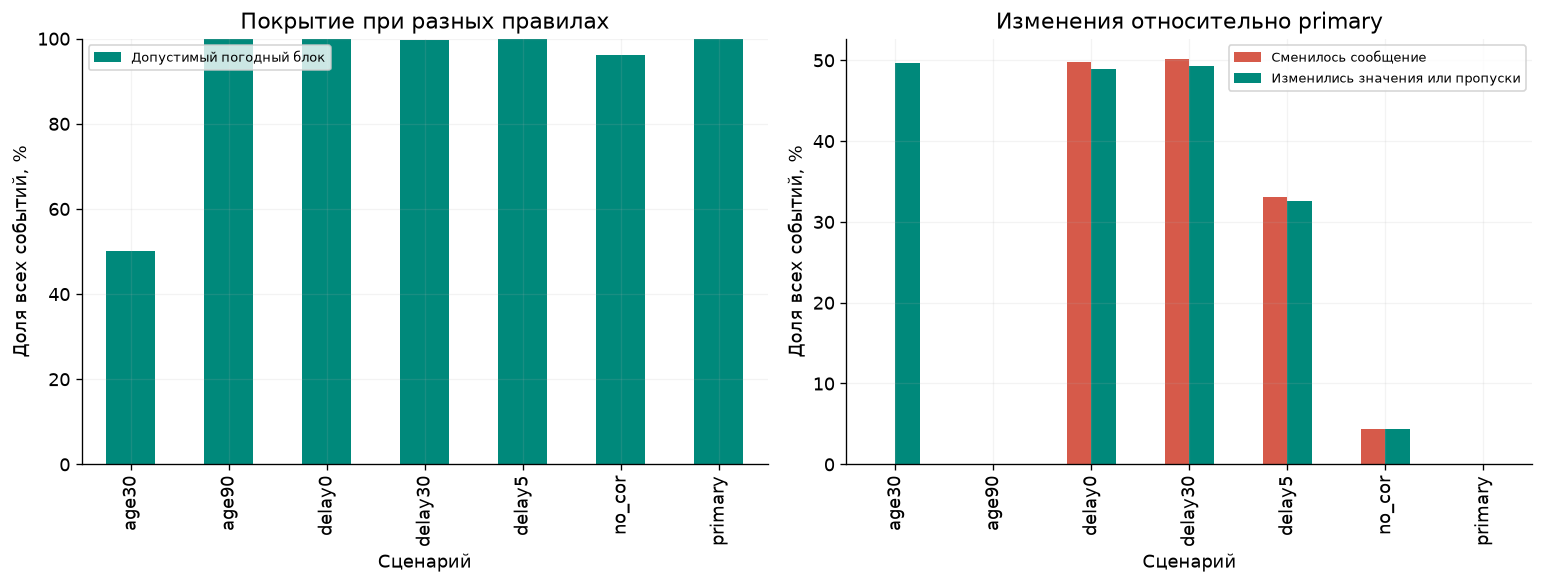

In [2]:
display(summary[['scenario','GoA','rows','usable_percent','message_changed_percent','information_changed_percent']])
overall=summary.groupby('scenario')[['rows','usable','message_changed','information_changed']].sum()
for field in ['usable','message_changed','information_changed']:overall[field+'_percent']=100*overall[field]/overall.rows
display(overall.reset_index())
fig,axes=plt.subplots(1,2,figsize=(13,5))
overall.usable_percent.plot.bar(ax=axes[0],color=GREEN,label='Допустимый погодный блок')
axes[0].set(ylabel='Доля всех событий, %',title='Покрытие при разных правилах',ylim=(0,100))
overall[['message_changed_percent','information_changed_percent']].plot.bar(ax=axes[1],color=[RED,GREEN])
axes[1].set(ylabel='Доля всех событий, %',title='Изменения относительно primary')
axes[1].legend(['Сменилось сообщение','Изменились значения или пропуски'],fontsize=8)
axes[0].legend(fontsize=8)
for ax in axes:ax.set_xlabel('Сценарий')
save('03_coverage_and_information')


## Неоднородность по аэропортам

Проценты рассчитаны внутри аэропорта. Они не стандартизованы по годам,
сезонам или метке. В no_cor исправления исключаются до поиска: исходная
неисправленная версия того же сообщения не восстанавливается.


scenario,delay0,delay5,delay30,age30,age90,no_cor
airport,,,,,,
EDDB,49.069006,32.861881,48.959794,50.059999,0.020224,1.064475
EDDF,48.651150,32.695220,49.801805,49.404754,0.020167,0.473420
EDDM,48.347371,31.954883,50.080888,49.116770,0.027527,0.946068
EGCC,49.647166,33.241837,48.691028,50.499228,0.017156,3.101733
EGLL,48.690872,32.274844,49.476507,49.583992,0.021687,39.100200
EGSS,48.903085,32.417731,49.372481,49.766431,0.019426,0.091259
EHAM,48.753920,32.320417,49.242628,49.734185,0.091544,0.640983
EIDW,48.972067,32.579326,49.071734,49.837994,0.061771,0.003411
EKCH,48.786543,32.538064,49.292561,49.612368,0.226084,0.066592


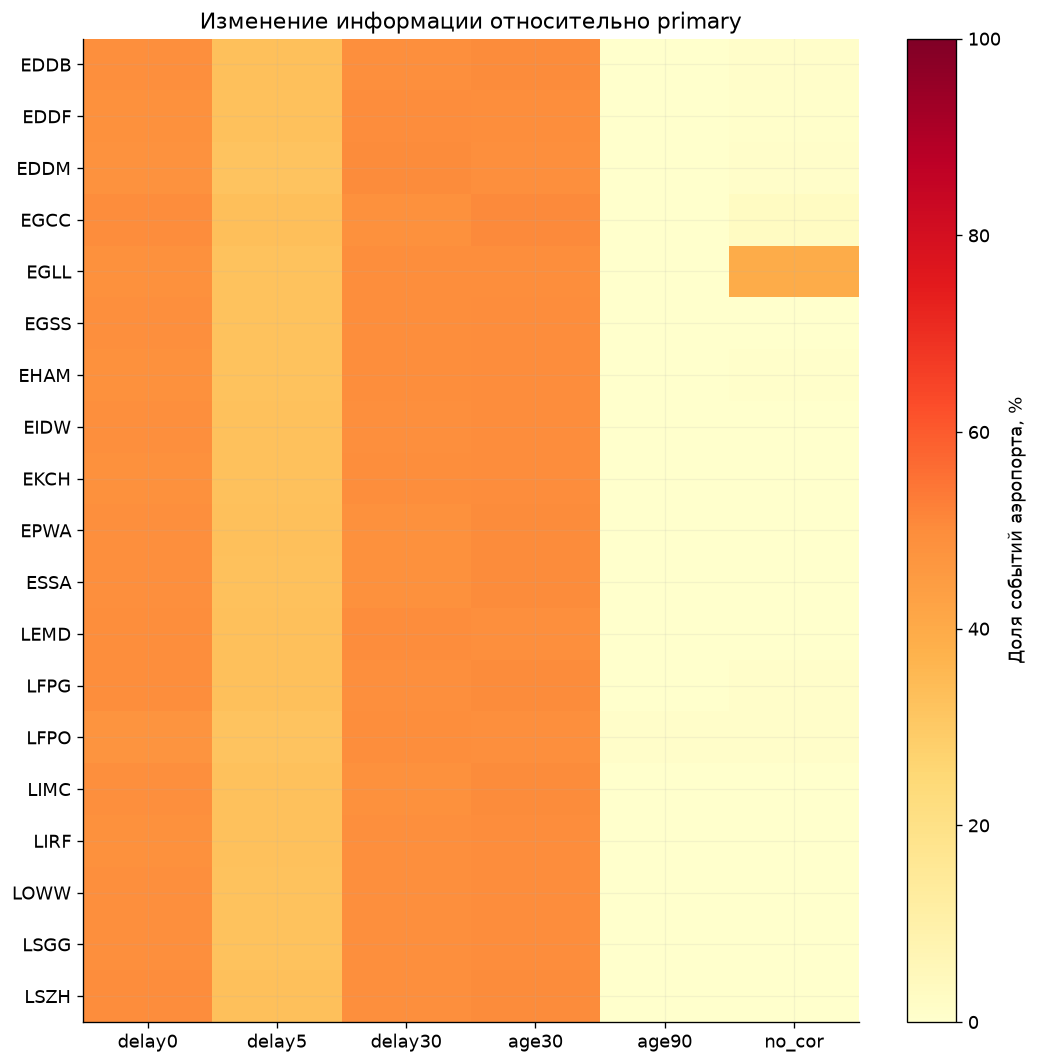

,scenario,field,rows,paired_present,missing_changed,value_changed,threshold_changed,absolute_difference_sum,value_changed_percent_of_pairs,missing_changed_percent_all,mean_absolute_difference
26,delay0,cavok,6331485,6322157,6271,131743,0,0.0,2.083830,0.099045,NaN
27,delay0,cloud_ceiling_ft,6331485,2026319,236585,603626,256054,655196100.0,29.789288,3.736643,323.343018
28,delay0,cumulonimbus_reported,6331485,6322157,6271,57159,0,0.0,0.904106,0.099045,NaN
29,delay0,dewpoint_c,6331485,6321952,6383,1107465,109212,1244617.0,17.517770,0.100814,0.196872
30,delay0,lowest_known_cloud_base_ft,6331485,3602399,189427,981942,315173,501766900.0,27.258002,2.991826,139.286875
31,delay0,present_weather_tokens,6331485,6322157,6271,331059,0,0.0,5.236488,0.099045,NaN
32,delay0,qnh_hpa,6331485,6322067,6321,638534,4593,643600.0,10.100083,0.099834,0.101802
33,delay0,temperature_c,6331485,6321974,6368,1362497,169648,1562695.0,21.551765,0.100577,0.247185
34,delay0,towering_cumulus_reported,6331485,6322157,6271,71533,0,0.0,1.131465,0.099045,NaN
35,delay0,visibility_m,6331485,6319713,7853,307773,246899,567017200.0,4.870047,0.124031,89.721986


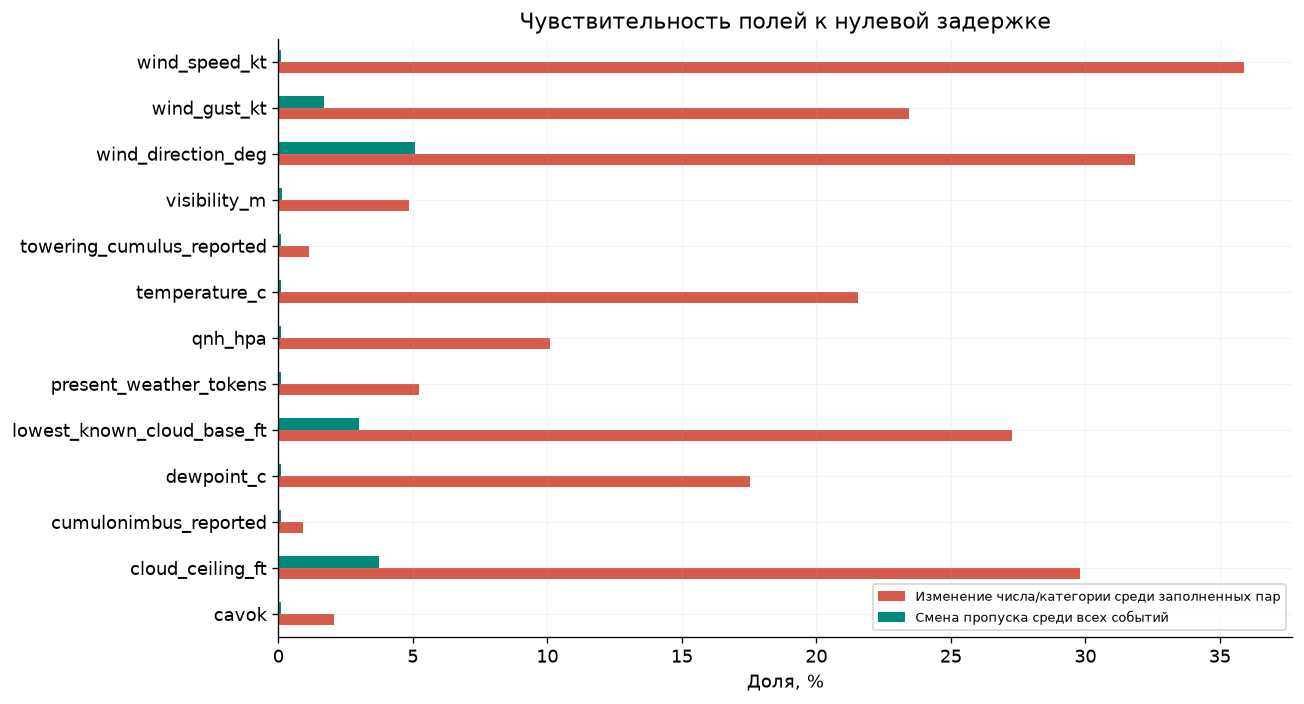

In [3]:
airport=strata.groupby(['airport','scenario'])[['rows','information_changed']].sum()
airport['percent']=100*airport.information_changed/airport.rows
pivot=airport.percent.unstack('scenario')[['delay0','delay5','delay30','age30','age90','no_cor']]
display(pivot)
fig,ax=plt.subplots(figsize=(9,9))
im=ax.imshow(pivot.to_numpy(),aspect='auto',cmap='YlOrRd',vmin=0,vmax=100)
ax.set_xticks(range(len(pivot.columns)),pivot.columns)
ax.set_yticks(range(len(pivot.index)),pivot.index)
ax.set(title='Изменение информации относительно primary')
fig.colorbar(im,ax=ax,label='Доля событий аэропорта, %')
save('04_airport_information_sensitivity')
fields=pd.read_csv(R/'03_field_differences.csv')
totals=fields.groupby(['scenario','field'])[['rows','paired_present','missing_changed','value_changed','threshold_changed','absolute_difference_sum']].sum().reset_index()
totals['value_changed_percent_of_pairs']=100*totals.value_changed/totals.paired_present.replace(0,np.nan)
totals['missing_changed_percent_all']=100*totals.missing_changed/totals.rows
totals['mean_absolute_difference']=totals.absolute_difference_sum/totals.paired_present.replace(0,np.nan)
totals.loc[totals.field.isin(['present_weather_tokens','cumulonimbus_reported','towering_cumulus_reported','cavok']),'mean_absolute_difference']=np.nan
display(totals.loc[totals.scenario.isin(['delay0','delay30','no_cor'])])
selected=totals.loc[totals.scenario.eq('delay0')].set_index('field')
fig,ax=plt.subplots(figsize=(11,6))
selected[['value_changed_percent_of_pairs','missing_changed_percent_all']].plot.barh(ax=ax,color=[RED,GREEN])
ax.set(xlabel='Доля, %',ylabel='',title='Чувствительность полей к нулевой задержке')
ax.legend(['Изменение числа/категории среди заполненных пар','Смена пропуска среди всех событий'],fontsize=8)
save('05_field_value_and_missingness')


## Устойчивость к временной неоднородности

Круговой блочный bootstrap календарных дней, парно для сценария и primary.
Все аэропорты одного дня переносятся совместно. Для каждого повторения $b$:
$$\Delta C_s^{(b)}=100\frac{\sum_{i\in b}(U_{is}-U_{i0})}{N_b}.$$
Интервалы - 2,5 и 97,5 процентили 2000 повторов, seed 20261011.
Это не ошибка измеренной доли полного корпуса и не интервал переносимости
на будущие годы. Длины блоков 7/14/28 дней проверяют зависимость результата
от принятой временной структуры.


,scenario,GoA,block_days,replicates,difference_pp,lower_pp,upper_pp
0,age30,False,7,2000,-49.703460,-49.745028,-49.660862
1,age30,False,14,2000,-49.703460,-49.751941,-49.654934
2,age30,False,28,2000,-49.703460,-49.758612,-49.645044
3,age30,True,7,2000,-50.013625,-50.713302,-49.238621
4,age30,True,14,2000,-50.013625,-50.752187,-49.301403
5,age30,True,28,2000,-50.013625,-50.764674,-49.247182
6,age90,False,7,2000,0.093313,0.082487,0.105916
7,age90,False,14,2000,0.093313,0.082288,0.106815
8,age90,False,28,2000,0.093313,0.082218,0.106592
9,age90,True,7,2000,0.114448,0.060623,0.175243


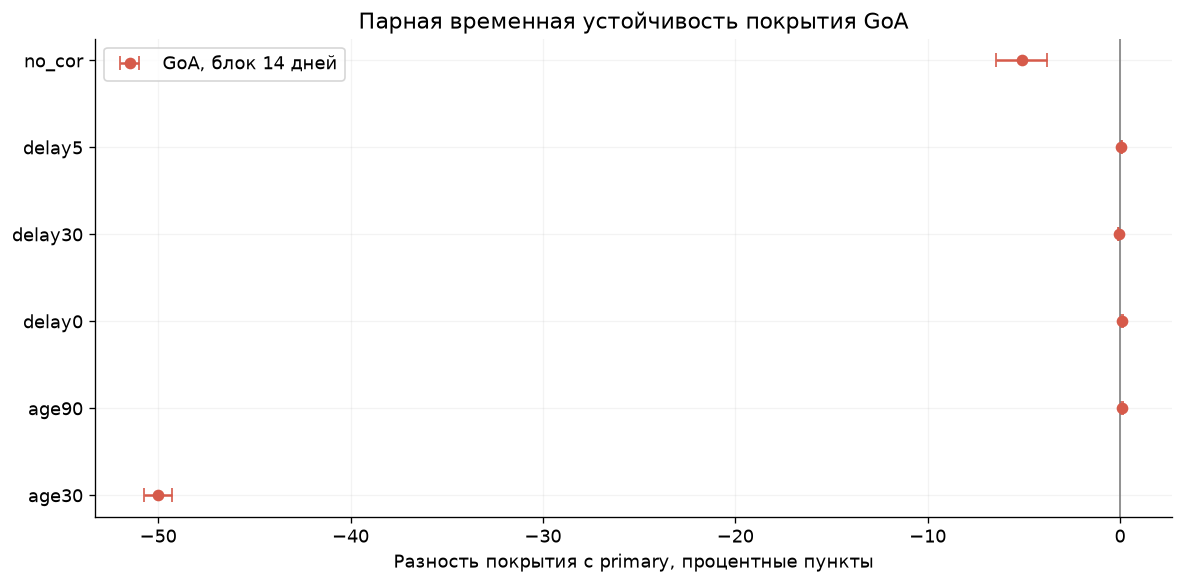

In [4]:
boot=pd.read_csv(R/'04_block_bootstrap.csv')
display(boot)
subset=boot.loc[boot.block_days.eq(14)&boot.GoA.eq(True)&boot.scenario.ne('primary')].reset_index(drop=True)
fig,ax=plt.subplots(figsize=(10,5))
ax.errorbar(subset.difference_pp,np.arange(len(subset)),xerr=[subset.difference_pp-subset.lower_pp,subset.upper_pp-subset.difference_pp],fmt='o',color=RED,capsize=4,label='GoA, блок 14 дней')
ax.set_yticks(range(len(subset)),subset.scenario)
ax.axvline(0,color='gray',linewidth=1)
ax.set(xlabel='Разность покрытия с primary, процентные пункты',title='Парная временная устойчивость покрытия GoA')
ax.legend()
save('06_block_bootstrap_goa')


Изменение закодированной видимости или высоты не всегда равно
изменению физической величины: специальные коды задают границы. Пороговые
различия в CSV являются описательными: 5 узлов, 30 градусов, 1000 м,
500 ft, 2 °C и 2 гПа; это не критерии опасности или очистки.
Модельная польза погоды и причинное влияние на GoA здесь не измерены.
